# Inference Pipelines

In this notebook, we redo some of the examples shown before using the builtin `Pipeline` functionality of `Cuneifit`.

Pipelines can use used to automatically construct parameter -> log-posterior functions without having to deal with manual vectorization or indexing.

In [1]:
import jax
from jax import numpy as jnp
from jax import scipy as jsc
from jax import random as jrd

import numpy as np
import matplotlib.pyplot as plt

import camb

import sys
sys.path.insert(0, "../")

import cuneifit

import pprint

try:
    from tqdm.notebook import tqdm
except:
    tqdm = lambda x: x

import sys

sys.path.insert(0, "cosmopower")

import cosmopower as cp
from cosmopower_jax.cosmopower_jax import CosmoPowerJAX

I0000 00:00:1793632761.741850   74038 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [2]:
# We'll use a simpler likelihood here to speed up calculations.
# In principle you can do the same with the Multi-Frequency likelihoods we used
# before!
like = cuneifit.CMBLite("act_dr6_cmbonly")
cmb = cuneifit.Cosmopower(yaml_file="jense_2024_emulators/jense_2023_cmb_camb_lcdm.yaml", root_dir="jense_2024_emulators")

# We can pass a series of priors directly to the Prior class and include them as well.
prior = cuneifit.Prior(
    lambda calG: jsc.stats.norm.logpdf(calG, loc=1.0, scale=0.003),
    lambda tau: jsc.stats.norm.logpdf(tau, loc=0.06, scale=0.01),
)

# But now we list them all in a single `Pipeline` instance:
pipeline = cuneifit.Pipeline(like, cmb, prior)

Assuming data rows are in the correct order as it was before version 1.0.
Failed to restore network derived: Failed to restore network from jense_2024_emulators/jense_2023_camb_lcdm/networks/jense_2023_camb_lcdm_derived:  does not exist..


E0000 00:00:1793632763.558753   74038 cuda_executor.cc:1737] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
W0000 00:00:1793632763.559060   74166 cuda_executor.cc:1755] Failed to determine cuDNN version (Note that this is expected if the application doesn't link the cuDNN plugin): INTERNAL: cuDNN error: CUDNN_STATUS_INTERNAL_ERROR
W0000 00:00:1793632763.587849   74038 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


Failed to restore network Hubble: Failed to restore network from jense_2024_emulators/jense_2023_camb_lcdm/networks/jense_2023_camb_lcdm_Hubble:  does not exist..
Failed to restore network angular_diameter_distance: Failed to restore network from jense_2024_emulators/jense_2023_camb_lcdm/networks/jense_2023_camb_lcdm_angular_diameter_distance:  does not exist..


In [3]:
# The Pipeline works similar to the functions we have seen before, for example we can check which parameters are used in the pipeline.
pprint.pprint(pipeline.parameters)

['calG', 'calT', 'calP', 'ombh2', 'omch2', 'logA', 'tau', 'ns', 'h']


In [4]:
# We don't need the temperature calibration (we use the dipole calibration instead for ACT DR6),
# so we mark it as "fixed" to unity.
fixed_parameters = {
    "calT": 1.0
}

# If we call the "restrict" function, the pipeline will keep all given parameters
# fixed to the values given.
pipeline.restrict(fixed_parameters)

# Notice that the aforementioned parameter will be gone.
pprint.pprint(pipeline.parameters)

['calG', 'calP', 'ombh2', 'omch2', 'logA', 'tau', 'ns', 'h']


In [5]:
# Now we can compute the log-posterior at the fiducial.
parameter_values = {
    "ombh2": 0.022,
    "omch2": 0.117,
    "h": 0.67,
    "ns": 0.97,
    "logA": 3.055,
    "tau": 0.06,

    "calG": 1.0,
    "calP": 1.0,
}

# We can use this function to directly turn our dictionary
# into a vector.
theta = pipeline.params_to_vec(parameter_values)
# We could also have done it manually:
# theta = jnp.array([ parameter_values[p] for p in pipeline.parameters ])

print(pipeline.logprior(theta))
print(pipeline.loglike(theta))
print(pipeline.logposterior(theta))

8.576436
-285.83942
-277.26297


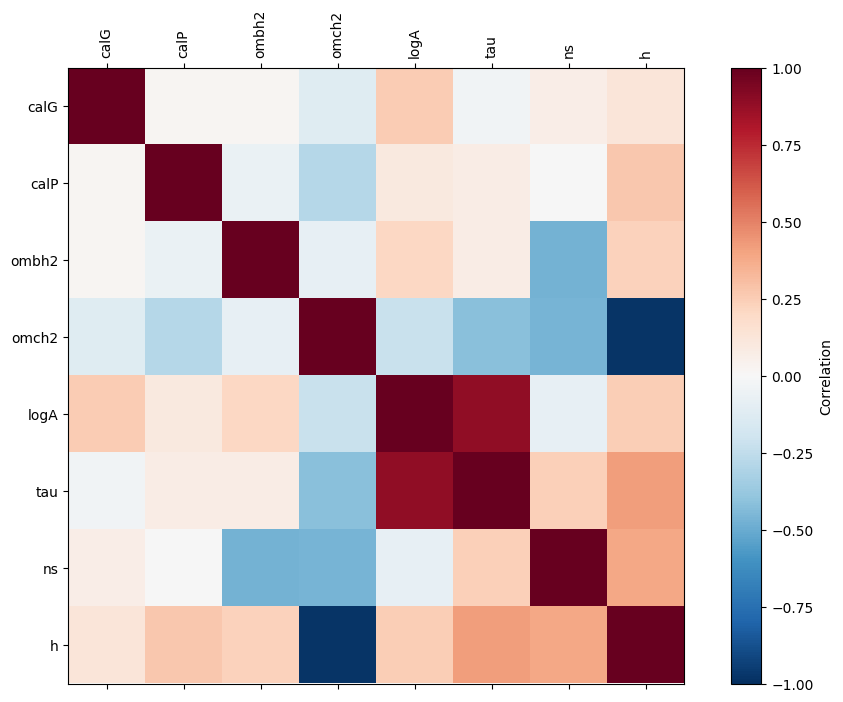

In [6]:
# We can compute the fisher matrix directly through the pipeline:
F = pipeline.fisher(theta)
cov = jnp.linalg.inv(F)
corr = cov / np.sqrt(np.diag(cov)[:,None] * np.diag(cov)[None,:])

fig, ax = plt.subplots(1, 1, figsize=(12, 8))

im = ax.matshow(corr, vmin=-1., vmax=1., cmap="RdBu_r")

ax.set_xticks(range(len(pipeline.parameters)))
ax.set_xticklabels(pipeline.parameters, rotation=90)
ax.set_yticks(range(len(pipeline.parameters)))
ax.set_yticklabels(pipeline.parameters)

fig.colorbar(im, ax=ax, label="Correlation");

In [10]:
# We can minimize a chain quickly:
logpost, bestfit = pipeline.minimize(theta, method="adam", min_steps=100, tqdm=tqdm, opt_args={"learning_rate": 1e-2})

# Do check out the documentation for the minimize function!
# You could, for example, run an ensemble of minimizers with random
# starting positions scattered around your suggested theta values.

0it [00:00, ?it/s]

In [12]:
print(logpost, bestfit)

[Array(182.78984, dtype=float32)] [Array([1.0001338 , 1.0003463 , 0.02260778, 0.12224375, 3.0662518 ,
       0.06421492, 0.9692769 , 0.666654  ], dtype=float32)]


In [14]:
from scipy import stats
import matplotlib.patches as mpt
import matplotlib.transforms as mtr

def add_ellipse(ax, m, s, cov, nstd=1., **kwargs):
    R = cov / (s[0] * s[1])
    erx = np.sqrt(1. + R)
    ery = np.sqrt(1. - R)

    nstd = np.sqrt(stats.chi2.ppf(2 * stats.norm.cdf(nstd) - 1, df=2))

    ell = mpt.Ellipse((0, 0), width=2*erx, height=2*ery, **kwargs)
    mx, my = m
    sx, sy = s

    tf = mtr.Affine2D().rotate_deg(45).scale(nstd*sx, nstd*sy).translate(mx, my)
    ell.set_transform(tf + ax.transData)
    ax.add_patch(ell)

bf = bestfit[0]
F_bf = pipeline.fisher(bf)
cov = jnp.linalg.inv(F_bf)

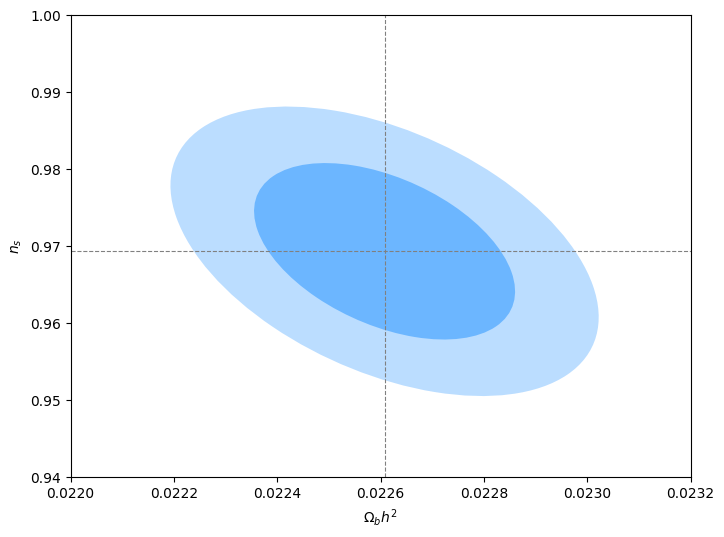

In [24]:
fig, ax = plt.subplots(1, 1, figsize=(8, 6))

i = pipeline.parameters.index("ombh2")
j = pipeline.parameters.index("ns")

add_ellipse(ax, (bf[i], bf[j]), (np.sqrt(np.diag(cov)[i]), np.sqrt(np.diag(cov)[j])), cov[i,j], nstd=1., alpha=0.5, fc="dodgerblue")
add_ellipse(ax, (bf[i], bf[j]), (np.sqrt(np.diag(cov)[i]), np.sqrt(np.diag(cov)[j])), cov[i,j], nstd=2., alpha=0.3, fc="dodgerblue")

ax.axvline(bf[i], c="grey", ls="--", lw=0.8)
ax.axhline(bf[j], c="grey", ls="--", lw=0.8)

ax.set_xlim(0.022, 0.0232)
ax.set_ylim(0.94, 1.0)

ax.set_xlabel(r"$\Omega_b h^2$")
ax.set_ylabel(r"$n_s$");